In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data.csv")
df["scenario"] = df["scenario"].astype(str).str.strip()
data = df[df["scenario"] == "02_MonthlySales"].copy()
print(data.shape)
data.head()

(12, 8)


,dataset_id,scenario,student_id,study_hours,prep_course,exam_score,stress_level,school_type
10,DS2,02_MonthlySales,M001,2023-01,TechStore,12000,150,TechStore
11,DS2,02_MonthlySales,M002,2023-02,TechStore,14500,160,TechStore
12,DS2,02_MonthlySales,M003,2023-03,TechStore,13000,155,TechStore
13,DS2,02_MonthlySales,M004,2023-04,TechStore,18000,190,TechStore
14,DS2,02_MonthlySales,M005,2023-05,TechStore,21000,210,TechStore


### Prepare data (order months, average revenue per company per month)

In [4]:
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]

data["prep_course"] = data["prep_course"].astype(str).str.strip().str[:3].str.title()
data["exam_score"] = pd.to_numeric(data["exam_score"], errors="coerce")
data["prep_course"] = pd.Categorical(data["prep_course"], categories=month_order, ordered=True)

pivot = (data.groupby(["prep_course", "school_type"], observed=True)["exam_score"]
             .mean()
             .unstack("school_type")
             .reindex(month_order))
pivot

C:\Users\HP\AppData\Local\Temp\ipykernel_16936\2188772440.py:5: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  data["prep_course"] = pd.Categorical(data["prep_course"], categories=month_order, ordered=True)


school_type
prep_course
Jan
Feb
Mar
Apr
May
Jun


### Line chart

C:\Users\HP\AppData\Local\Temp\ipykernel_16936\954654280.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Company")


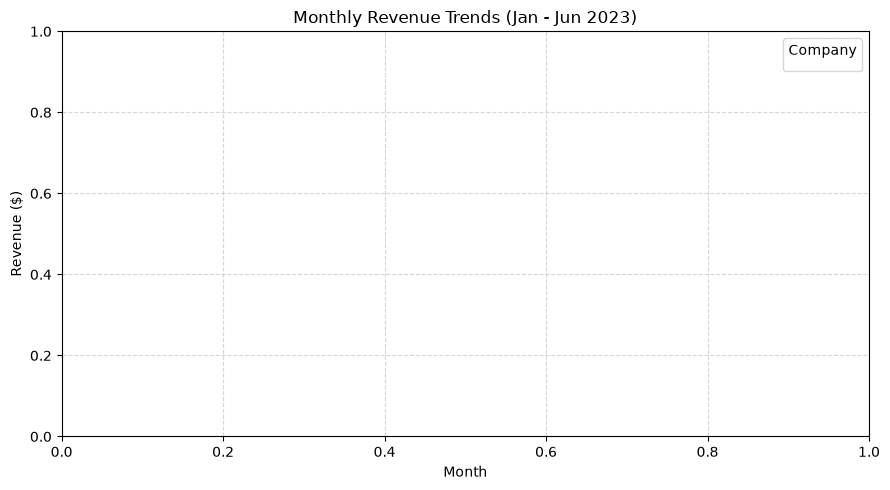

In [5]:
plt.figure(figsize=(9, 5))

for company in pivot.columns:
    plt.plot(pivot.index, pivot[company], marker="o", label=company)

plt.title("Monthly Revenue Trends (Jan - Jun 2023)")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.legend(title="Company")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()